# Lecture 3 - Computer demonstration

Jupyter is a program where you can write notebooks which mixes both text (Markdown formatted, including math formulas), code and output (both text and graphics)

Sagemath is a bunch of Python libraries (modules) together with an interpreter which makes it easier to do mathematics.

In [1]:
2^3

8

Let us compute $\int x \sin(\sqrt{x}) dx$

In [2]:
I = integrate(x * sin(sqrt(x)), x)    # x is already conveniently defined as a sage symbol 
I

-2*(x^(3/2) - 6*sqrt(x))*cos(sqrt(x)) + 6*(x - 2)*sin(sqrt(x))

You can make it pretty by the command `show`

In [3]:
show(I)

-2*(x^(3/2) - 6*sqrt(x))*cos(sqrt(x)) + 6*(x - 2)*sin(sqrt(x))

At the same time it is regular Python so you can do `for`-loops and define functions

In [4]:
def fibonacci(n):
    if n == 0 or n == 1:
        return n
    else:
        return fibonacci(n-1) + fibonacci(n-2)

In [5]:
for n in [1..10]:   # it is also easier to write intervals in sage compared to regular python
    print(n, fibonacci(n))

1 1
2 1
3 2
4 3
5 5
6 8
7 13
8 21
9 34
10 55


In [6]:
table([ [n, fibonacci(n)] for n in [1..10] ])

\(1\),\(1\)
\(2\),\(1\)
\(3\),\(2\)
\(4\),\(3\)
\(5\),\(5\)
\(6\),\(8\)
\(7\),\(13\)
\(8\),\(21\)
\(9\),\(34\)
\(10\),\(55\)


Sage converts integers you type, like 10, into special objects so that you can easily do rational artimetics

In [7]:
4/3 + 3/7

37/21

If we force it to use regular python ints instead we get

In [8]:
int(4)/int(3)

1.3333333333333333

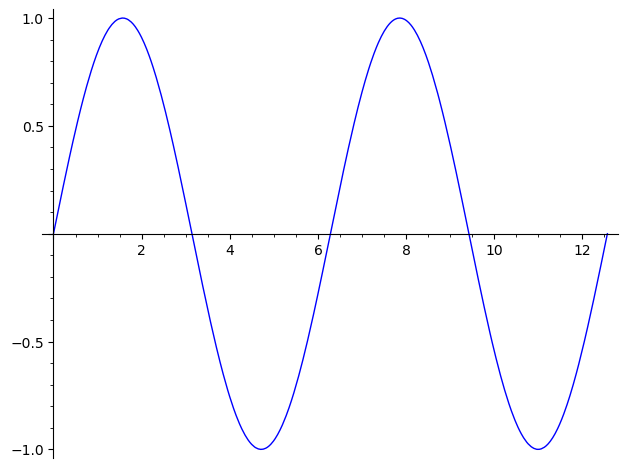

In [9]:
plot(sin(x), (x, 0, 4*pi))

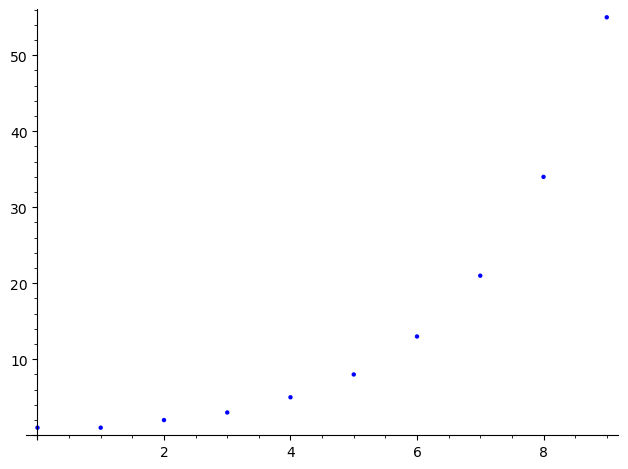

In [10]:
list_plot([fibonacci(n) for n in [1..10]])

We can import other python modules

In [11]:
import random

In [12]:
random.randint(0,10)  # IMPORTANT: this random generator is not good for cryptography

4

In [13]:
import secrets

In [14]:
secrets.randbelow(10)  # This is better

8

The default `random` is useful because you can set the `seed` so that when you are trying out things you always get the same results

In [15]:
random.seed?

Signature:      random.seed(self, a=None, version=2)
Docstring:     
Initialize internal state from a seed.

The only supported seed types are None, int, float, str, bytes, and
bytearray.

None or no argument seeds from current time or from an operating
system specific randomness source if available.

If *a* is an int, all bits are used.

For version 2 (the default), all of the bits are used if *a* is a str,
bytes, or bytearray.  For version 1 (provided for reproducing random
sequences from older versions of Python), the algorithm for str and
bytes generates a narrower range of seeds.
Init docstring: Initialize self.  See help(type(self)) for accurate signature.
File:           /opt/homebrew/Caskroom/miniforge/base/envs/sage109/lib/python3.13/random.py
Type:           method

In [16]:
random.seed("crypto-course")

In [17]:
[random.random() for i in [1..5]]

[0.1926566435420507,
 0.6060053535773472,
 0.5976716721409703,
 0.08102999549866285,
 0.7433256411207996]

## Caesar cipher

In [18]:
alphabet = "ABCDEFGHIJKLMNOPQRSTUVWXYZ"
N = len(alphabet)

def encode(ch):
    return alphabet.index(ch)

def decode(i):
    return alphabet[i]

In [19]:
[decode(x) for x in [7, 4, 11, 11, 14, 22, 14, 17, 11, 3]]

['H', 'E', 'L', 'L', 'O', 'W', 'O', 'R', 'L', 'D']

In [20]:
"".join(['H', 'E', 'L', 'L', 'O', 'W', 'O', 'R', 'L', 'D'])

'HELLOWORLD'

In [21]:
def e(k, m):
    return Mod(m + k, N)

def d(k, m):
    return Mod(m - k, N)

In [22]:
text = "HELLOWORLD"
message = [encode(ch) for ch in text]
message

[7, 4, 11, 11, 14, 22, 14, 17, 11, 3]

In [23]:
cipher = [e(13, m) for m in message]
cipher

[20, 17, 24, 24, 1, 9, 1, 4, 24, 16]

In [24]:
[decode(x) for x in [d(13, c) for c in cipher]]

['H', 'E', 'L', 'L', 'O', 'W', 'O', 'R', 'L', 'D']